# 中金 · 股/债/金多资产回撤控制复现

原文第三部分：用与股债完全相同的方法，再定义**股金**、**债金**两个「双杀」预警，
在股:债:金 = 2:6:2 的基准组合上做回撤控制。

| 项 | 原文 | 本复现 |
|---|---|---|
| 资产 | 沪深300、中债综合财富、黄金现货 | 沪深300、中债综合财富、**黄金ETF（518880，后复权）** |
| 样本期 | 2004/04 – 2020/12 | **2013/07 起**；与原文重叠 2014–2020，2021 起为样本外 |
| 预警 | 三对资产各自按股债预警的规则 | 同；60 日窗口内秩变换、点估计判零 |
| 解除条件里看谁的趋势 | 股债看债券；**股金、债金未说明** | 主口径：看较稳健的一方（股金看金、债金看债），另做敏感性 |
| 仓位规则 | n=0 基准；n=1 触发的两资产转货币基金；n≥2 全部货币基金 | 同；t 日收盘状态，t+1 日执行；货币年化 2% |
| 基准再平衡 | 未说明 | 每日再平衡到 2:6:2 |

**为什么用黄金 ETF**：免费的上海金交所 Au99.99 数据只有 2016-12 以后。COMEX 金价换算成人民币的版本
与 Au99.99 的日收益相关只有 0.35（错开一天对齐后 0.66），因为 COMEX 在北京时间凌晨收盘，与 A 股不同步。
黄金 ETF 518880 在上交所交易、与 A 股同时段收盘，2017 年以来与 Au99.99 日收益相关 0.97，
与股、债的相关系数也几乎相同。代价是只能从 2013 年 7 月开始，**原文 2004–2013 年无法可靠复现**。

## 0 · 环境与数据

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tailrisk").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tailrisk import data, signals as sg, backtest as bt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (13, 4),
    "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})

NAMES = {"股": "沪深300", "债": "中债综合财富", "金": "黄金ETF"}
prices = data.load_prices(list(NAMES.values())).rename(columns={v: k for k, v in NAMES.items()})
returns = data.to_returns(prices)
BASE_W = {"股": 0.2, "债": 0.6, "金": 0.2}
IN_SAMPLE = slice("2014-01-01", "2020-12-31")      # 与原文重叠的完整年份
OUT_SAMPLE = slice("2021-01-01", "2025-12-31")     # 原文发表后的完整年份
print(f"共同交易日 {len(prices)} 天：{prices.index.min():%Y-%m-%d} ~ {prices.index.max():%Y-%m-%d}")

共同交易日 3208 天：2013-07-29 ~ 2026-10-12


In [2]:
# 黄金 ETF 与上海金交所现货的对照（2017 年起两者都有数据）
sge = data.load_series("黄金Au9999")
chk = pd.DataFrame({"黄金ETF": returns["金"], "Au99.99": sge.pct_change(fill_method=None),
                    "股": returns["股"], "债": returns["债"]}).loc["2017-01-01":].dropna()
chk.corr().round(3)

,黄金ETF,Au99.99,股,债
黄金ETF,1.000,0.968,0.089,0.097
Au99.99,0.968,1.000,0.093,0.087
股,0.089,0.093,1.000,-0.215
债,0.097,0.087,-0.215,1.000


## 1 · 三对预警

规则与股债预警相同：触发 = λ_D>0 且 λ_U=0 且两者至少一方 DIF<0；解除 = λ_D=0 且指定一方 DIF>0。

In [3]:
RELEASE_MAIN = {("股", "债"): "债", ("股", "金"): "金", ("债", "金"): "债"}

def build_warnings(release_map):
    out = {}
    for (a, b), rel in release_map.items():
        s = sg.pair_warning(prices, returns, a, b, release_on=rel)
        out[(a, b)] = s["预警中"]
    return out

warn = build_warnings(RELEASE_MAIN)
pd.DataFrame({f"{a}{b}": {"预警天数占比": w.mean(), "预警次数": len(sg.episodes(w)),
                          "平均持续交易日": sg.episodes(w)["持续交易日"].mean()}
              for (a, b), w in warn.items()}).T.style.format({"预警天数占比": "{:.1%}", "预警次数": "{:.0f}",
                                                             "平均持续交易日": "{:.1f}"})

,预警天数占比,预警次数,平均持续交易日
股债,7.7%,14,17.3
股金,23.3%,18,40.7
债金,24.3%,13,58.8


## 2 · 回测与原文逐年对照

In [4]:
def run(warnings_dict, R=returns.loc["2014-01-01":]):
    daily = {k: v.reindex(R.index, method="ffill").fillna(False) for k, v in warnings_dict.items()}
    strat, n = bt.pairwise_cash_overlay(R, BASE_W, daily, cash_rate=0.02)
    base = (R[list(BASE_W)] * pd.Series(BASE_W)).sum(axis=1)
    return strat, base, n

strat, base, n = run(warn)
print("每日预警触发数 n 的分布：", n.value_counts(normalize=True).sort_index().round(3).to_dict())

CICC = pd.DataFrame({
    "策略年最大回撤": [-1.56, -10.00, -4.03, -2.63, -5.14, -2.64, -5.45],
    "基准年最大回撤": [-1.56, -10.09, -4.88, -2.63, -5.22, -2.64, -5.45],
    "策略年收益": [15.57, 4.69, 1.46, 6.61, -0.68, 13.28, 8.81],
    "基准年收益": [15.33, 4.87, 0.61, 6.51, -1.30, 12.85, 10.90],
}, index=range(2014, 2021)) / 100

yt = bt.yearly_table(pd.DataFrame({"策略": strat, "基准": base}))
ours = pd.DataFrame({"策略年最大回撤": yt[("策略", "年最大回撤")], "基准年最大回撤": yt[("基准", "年最大回撤")],
                     "策略年收益": yt[("策略", "年收益")], "基准年收益": yt[("基准", "年收益")]})
pd.concat({"原文": CICC, "复现": ours.loc[2014:2020]}, axis=1).style.format("{:.2%}")

每日预警触发数 n 的分布： {0: 0.501, 1: 0.441, 2: 0.059}


**判读**：

- 基准组合的逐年收益和回撤与原文接近，说明数据口径（尤其是用黄金 ETF 代替现货）可以接受。
- 策略的逐年结果与原文有出入：复现在 2015–2018 年的回撤改善比原文大，2014 年收益则明显落后。
  原文没有披露三对预警各自的触发时点，无法逐次核对差异来源。

## 3 · 按原文口径汇总：年平均最大回撤与年平均收益

In [5]:
def cicc_summary(tbl):
    d_mdd = tbl["策略年最大回撤"] - tbl["基准年最大回撤"]      # >0 表示回撤变小
    d_ret = tbl["策略年收益"] - tbl["基准年收益"]
    return {"年数": len(tbl), "年平均最大回撤降低": d_mdd.mean(), "回撤下降的年数": int((d_mdd > 1e-6).sum()),
            "回撤上升的年数": int((d_mdd < -1e-6).sum()),
            "年平均收益提升": d_ret.mean(), "收益提升的年数": int((d_ret > 1e-6).sum())}

summary = pd.DataFrame({
    "原文 2004–2020": cicc_summary(pd.DataFrame({
        "策略年最大回撤": [-6.82, -3.45, -4.85, -3.91, -5.63, -5.63, -5.99, -3.96, -2.89, -8.73] + list(CICC["策略年最大回撤"] * 100),
        "基准年最大回撤": [-6.82, -3.45, -4.85, -4.02, -19.69, -5.63, -4.35, -5.47, -3.02, -9.76] + list(CICC["基准年最大回撤"] * 100),
        "策略年收益": [-6.08, 7.75, 24.54, 19.30, 6.91, 18.84, 1.38, 3.23, 2.34, -3.97] + list(CICC["策略年收益"] * 100),
        "基准年收益": [-5.67, 7.75, 24.01, 28.48, -10.17, 18.84, 3.15, -0.47, 4.49, -6.74] + list(CICC["基准年收益"] * 100),
    }) / 100),
    "原文 2014–2020": cicc_summary(CICC),
    "复现 2014–2020": cicc_summary(ours.loc[2014:2020]),
    "复现 样本外 2021–2025": cicc_summary(ours.loc[2021:2025]),
}).T
summary.style.format({"年平均最大回撤降低": "{:.2%}", "年平均收益提升": "{:.2%}"})

,年数,年平均最大回撤降低,回撤下降的年数,回撤上升的年数,年平均收益提升,收益提升的年数
原文 2004–2020,17.000000,0.95%,8.000000,1.000000,0.62%,9.000000
原文 2014–2020,7.000000,0.15%,3.000000,0.000000,-0.00%,5.000000
复现 2014–2020,7.000000,1.14%,4.000000,1.000000,0.30%,5.000000
复现 样本外 2021–2025,5.000000,0.41%,2.000000,3.000000,-2.63%,2.000000


### 3.1 原文的汇总数字有多依赖 2008 年？

原文 2008 年基准回撤 −19.69%、策略只有 −5.63%，收益从 −10.17% 变为 +6.91%，单这一年的差距就远大于其余年份。
把 2008 年去掉重算原文自己的数字：

In [6]:
cicc_full = pd.DataFrame({
    "策略年最大回撤": [-6.82, -3.45, -4.85, -3.91, -5.63, -5.63, -5.99, -3.96, -2.89, -8.73] + list(CICC["策略年最大回撤"] * 100),
    "基准年最大回撤": [-6.82, -3.45, -4.85, -4.02, -19.69, -5.63, -4.35, -5.47, -3.02, -9.76] + list(CICC["基准年最大回撤"] * 100),
    "策略年收益": [-6.08, 7.75, 24.54, 19.30, 6.91, 18.84, 1.38, 3.23, 2.34, -3.97] + list(CICC["策略年收益"] * 100),
    "基准年收益": [-5.67, 7.75, 24.01, 28.48, -10.17, 18.84, 3.15, -0.47, 4.49, -6.74] + list(CICC["基准年收益"] * 100),
}, index=range(2004, 2021)) / 100
pd.DataFrame({"原文 全部 17 年": cicc_summary(cicc_full),
              "原文 去掉 2008 年": cicc_summary(cicc_full.drop(2008))}).T.style.format(
    {"年平均最大回撤降低": "{:.2%}", "年平均收益提升": "{:.2%}"})

,年数,年平均最大回撤降低,回撤下降的年数,回撤上升的年数,年平均收益提升,收益提升的年数
原文 全部 17 年,17.000000,0.95%,8.000000,1.000000,0.62%,9.000000
原文 去掉 2008 年,16.000000,0.13%,7.000000,1.000000,-0.41%,8.000000


**判读**：去掉 2008 年后，原文自己的数据里，年平均回撤只降低约 0.1 个百分点，年平均收益反而下降。
「年平均最大回撤降低 0.95%、年平均收益提升 0.62%」这一结论几乎完全来自 2008 年一年。

### 3.2 复现的全期绩效

In [7]:
full = {}
for name, W in [("2014–2020", IN_SAMPLE), ("样本外 2021–2025", OUT_SAMPLE)]:
    full[(name, "基准 2:6:2")] = bt.perf_stats(base.loc[W])
    full[(name, "加预警")] = bt.perf_stats(strat.loc[W])
pd.DataFrame(full).T.style.format("{:.2%}", subset=["年化收益", "年化波动", "最大回撤"]).format(
    "{:.2f}", subset=["收益波动比", "超额夏普", "卡玛比率"])

## 4 · 解除规则敏感性

原文只说「使用完全相同的方法」，没有说股金、债金预警解除时看哪一方的上涨趋势。
逐一列出可能的口径。**这里只是报告差异，不从中挑选回测最好的口径。**

In [8]:
variants = {
    "主口径：股金看金、债金看债": RELEASE_MAIN,
    "股金看股、债金看债": {("股", "债"): "债", ("股", "金"): "股", ("债", "金"): "债"},
    "股金看金、债金看金": {("股", "债"): "债", ("股", "金"): "金", ("债", "金"): "金"},
    "股金看股、债金看金": {("股", "债"): "债", ("股", "金"): "股", ("债", "金"): "金"},
}
rows = {}
for name, rmap in variants.items():
    s, b, nn = run(build_warnings(rmap))
    y = bt.yearly_table(pd.DataFrame({"策略": s, "基准": b}))
    t = pd.DataFrame({"策略年最大回撤": y[("策略", "年最大回撤")], "基准年最大回撤": y[("基准", "年最大回撤")],
                      "策略年收益": y[("策略", "年收益")], "基准年收益": y[("基准", "年收益")]})
    rows[name] = {"n=0 天数占比": (nn == 0).mean(),
                  **{f"2014–20 {k}": v for k, v in cicc_summary(t.loc[2014:2020]).items() if k in ("年平均最大回撤降低", "年平均收益提升")},
                  **{f"样本外 {k}": v for k, v in cicc_summary(t.loc[2021:2025]).items() if k in ("年平均最大回撤降低", "年平均收益提升")}}
pd.DataFrame(rows).T.style.format("{:.2%}")

,n=0 天数占比,2014–20 年平均最大回撤降低,2014–20 年平均收益提升,样本外 年平均最大回撤降低,样本外 年平均收益提升
主口径：股金看金、债金看债,50.08%,1.14%,0.30%,0.41%,-2.63%
股金看股、债金看债,47.41%,1.04%,0.24%,0.58%,-2.65%
股金看金、债金看金,49.56%,1.08%,0.17%,0.41%,-2.63%
股金看股、债金看金,46.89%,0.99%,0.12%,0.58%,-2.66%


**判读**：四种解除口径的结果相差很小，这个原文未说明的细节不影响结论。

## 5 · 安慰剂检验：换成随机时点的预警会怎样？

把每一对预警序列各自随机循环平移（保留预警的天数、次数和持续时间，只打乱发生的时点），
重复 500 次，得到「同样频率、同样持续时间的随机预警」带来的年平均回撤降低和收益提升的分布。
真实预警若真有择时能力，应明显好于大多数随机版本。

In [9]:
R = returns.loc["2014-01-01":]
daily_main = {k: v.reindex(R.index, method="ffill").fillna(False).astype(bool) for k, v in warn.items()}

def summary_of(daily, W):
    s, nn = bt.pairwise_cash_overlay(R, BASE_W, daily, cash_rate=0.02)
    y = bt.yearly_table(pd.DataFrame({"策略": s, "基准": base}))
    t = pd.DataFrame({"策略年最大回撤": y[("策略", "年最大回撤")], "基准年最大回撤": y[("基准", "年最大回撤")],
                      "策略年收益": y[("策略", "年收益")], "基准年收益": y[("基准", "年收益")]})
    c = cicc_summary(t.loc[W])
    return c["年平均最大回撤降低"], c["年平均收益提升"]

rng = np.random.default_rng(42)
placebo = {"2014–2020": [], "样本外 2021–2025": []}
for _ in range(500):
    shifted = {k: pd.Series(np.roll(v.values, rng.integers(60, len(v) - 60)), index=v.index) for k, v in daily_main.items()}
    for key, W in [("2014–2020", slice(2014, 2020)), ("样本外 2021–2025", slice(2021, 2025))]:
        placebo[key].append(summary_of(shifted, W))

rows = {}
for key, W in [("2014–2020", slice(2014, 2020)), ("样本外 2021–2025", slice(2021, 2025))]:
    actual = summary_of(daily_main, W)
    P = np.array(placebo[key])
    rows[key] = {"真实：年平均回撤降低": actual[0], "随机中位数：回撤降低": np.median(P[:, 0]),
                 "随机中不如真实的比例（回撤）": (P[:, 0] < actual[0]).mean(),
                 "真实：年平均收益提升": actual[1], "随机中位数：收益提升": np.median(P[:, 1]),
                 "随机中不如真实的比例（收益）": (P[:, 1] < actual[1]).mean()}
pd.DataFrame(rows).T.style.format("{:.2%}")

,真实：年平均回撤降低,随机中位数：回撤降低,随机中不如真实的比例（回撤）,真实：年平均收益提升,随机中位数：收益提升,随机中不如真实的比例（收益）
2014–2020,1.14%,0.68%,79.40%,0.30%,-2.00%,97.80%
样本外 2021–2025,0.41%,0.25%,69.40%,-2.63%,-1.58%,18.40%


「随机中不如真实的比例」接近 100% 说明真实预警的择时明显优于随机；接近 50% 说明和随机时点差不多。
注意减仓本身（无论时点）就会降低回撤、拖累收益，所以要和随机版本比，而不是和基准比。

**判读**：

- 2014–2020 年：回撤降低只好于约八成随机版本，不算显著；收益提升好于约 98% 的随机版本，择时在这段时间看起来有效。
- 样本外 2021–2025 年：收益提升不如八成以上的随机版本 —— 样本内的择时效果没有延续。

## 6 · 净值

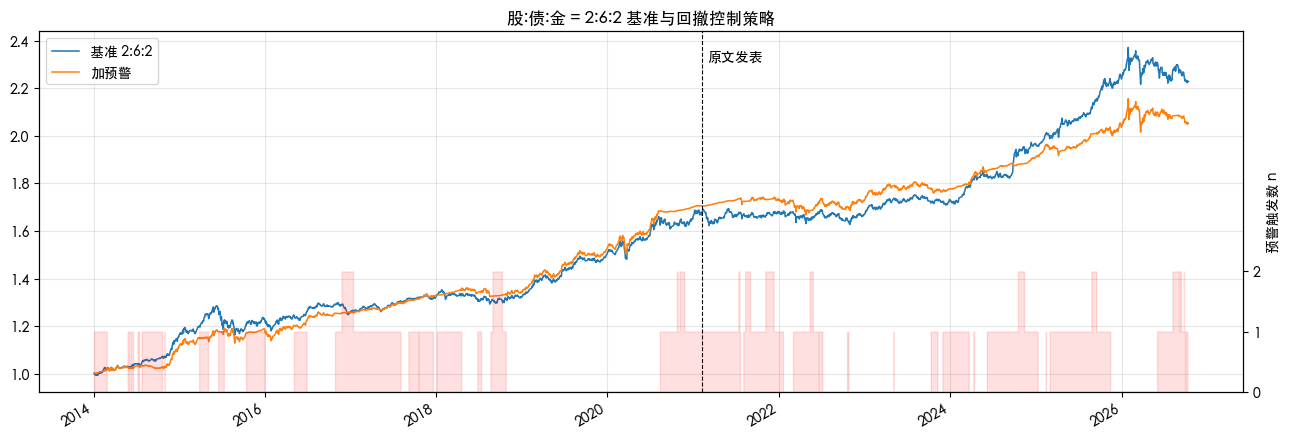

In [10]:
nav = (1 + pd.DataFrame({"基准 2:6:2": base, "加预警": strat})).cumprod()
fig, ax = plt.subplots(figsize=(13, 4.5))
nav.plot(ax=ax, lw=1.1)
ax2 = ax.twinx()
ax2.fill_between(n.index, 0, n.values, step="post", color="red", alpha=.12)
ax2.set_ylim(0, 6); ax2.set_yticks([0, 1, 2]); ax2.set_ylabel("预警触发数 n")
ax.axvline(pd.Timestamp("2021-02-05"), color="k", ls="--", lw=.8)
ax.text(pd.Timestamp("2021-03-01"), ax.get_ylim()[1] * .97, "原文发表", va="top")
ax.set_title("股:债:金 = 2:6:2 基准与回撤控制策略"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
# 结论

| 问题 | 结论 |
|---|---|
| 数据能否对上原文 | **基本可以**。2014–2020 年基准组合的逐年收益和回撤与原文接近；2004–2013 年缺少同步的黄金数据，无法复现 |
| 原文汇总结论的来源 | **几乎完全来自 2008 年**。去掉这一年，原文自己的数据里回撤只降约 0.1 个百分点，收益反而下降 |
| 2014–2020 年复现 | 回撤改善比原文同期更大，收益略有提升；与随机时点的预警相比，收益择时较好，回撤改善不显著 |
| 原文发表后（2021–2025） | **不成立**。年平均收益下降约 2.6 个百分点，不如八成以上的随机预警；主要因为 2024、2025 年约四分之三的时间里黄金被预警移出组合，而黄金这两年分别上涨 27.5%、56.9% |
| 原文未说明的解除规则 | 四种口径结果几乎相同，不影响结论 |

下方为自动汇总的关键数字。

In [11]:
s = summary
print(f"原文 2014–2020：年平均回撤降低 {s.loc['原文 2014–2020', '年平均最大回撤降低']:.2%}，年平均收益提升 {s.loc['原文 2014–2020', '年平均收益提升']:.2%}")
print(f"复现 2014–2020：年平均回撤降低 {s.loc['复现 2014–2020', '年平均最大回撤降低']:.2%}，年平均收益提升 {s.loc['复现 2014–2020', '年平均收益提升']:.2%}")
print(f"复现 样本外：  年平均回撤降低 {s.loc['复现 样本外 2021–2025', '年平均最大回撤降低']:.2%}，年平均收益提升 {s.loc['复现 样本外 2021–2025', '年平均收益提升']:.2%}")

原文 2014–2020：年平均回撤降低 0.15%，年平均收益提升 -0.00%
复现 2014–2020：年平均回撤降低 1.14%，年平均收益提升 0.30%
复现 样本外：  年平均回撤降低 0.41%，年平均收益提升 -2.63%
